# Evaluating Operating-System Random Number Generators

**Objective:** Evaluate OS random-number generation mechanisms and check how suitable they are for cryptography.

**Sources compared (1 MiB each):**
1. Linux `/dev/urandom`
2. OpenSSL `openssl rand`
3. Windows CNG / .NET `RandomNumberGenerator`

**Notebook layout**
- Part 1: load the data
- Part 2 (Task 2): byte-frequency, bit, repeated-pattern and serial-correlation analysis
- Part 3 (Task 3): statistical tests and interpretation
- Part 4 (Task 4): how Linux and Windows generate secure random data
- Part 5 (Task 5): comparison, and why passing the tests is NOT proof of security

## Part 1: Load the data

In [1]:
import hashlib, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import erfc

# find the datasets folder (works if the notebook is run from analysis/ or from the repo root)
DATA_DIR = next(p for p in [Path("../datasets"), Path("datasets")] if p.exists())

FILES = {
    "Linux /dev/urandom": DATA_DIR / "urandom.bin",
    "OpenSSL rand":       DATA_DIR / "openssl.bin",
    "Windows CNG/.NET":   DATA_DIR / "windows_cng.bin",
}
ALPHA = 0.01   # a test FAILS if its p-value is below this

data = {}
rows = []
for name, path in FILES.items():
    raw = path.read_bytes()
    data[name] = np.frombuffer(raw, dtype=np.uint8)
    rows.append([name, path.name, len(raw), len(raw) >= 1024 * 1024,
                 hashlib.sha256(raw).hexdigest()[:16] + "..."])

pd.DataFrame(rows, columns=["Source", "File", "Size (bytes)", ">= 1 MiB ?", "SHA-256 (start)"])

,Source,File,Size (bytes),>= 1 MiB ?,SHA-256 (start)
0,Linux /dev/urandom,urandom.bin,1048576,True,4962e7aadd31a84b...
1,OpenSSL rand,openssl.bin,1048576,True,ce58b5fc14dc7cd4...
2,Windows CNG/.NET,windows_cng.bin,1048576,True,7e1728cce357b770...


## Part 2 (Task 2): Analysis

For truly random bytes we expect:
- **Byte frequency:** every value 0-255 appears about equally often (`N/256` times each).
- **Bit distribution:** about 50% ones and 50% zeros, in every bit position.
- **Repeated patterns:** only as many repeats as pure chance gives (the "birthday" effect), no more.
- **Serial correlation:** no link between a byte and the byte(s) that follow it (correlation close to 0).

### 2.1 Byte-frequency distribution

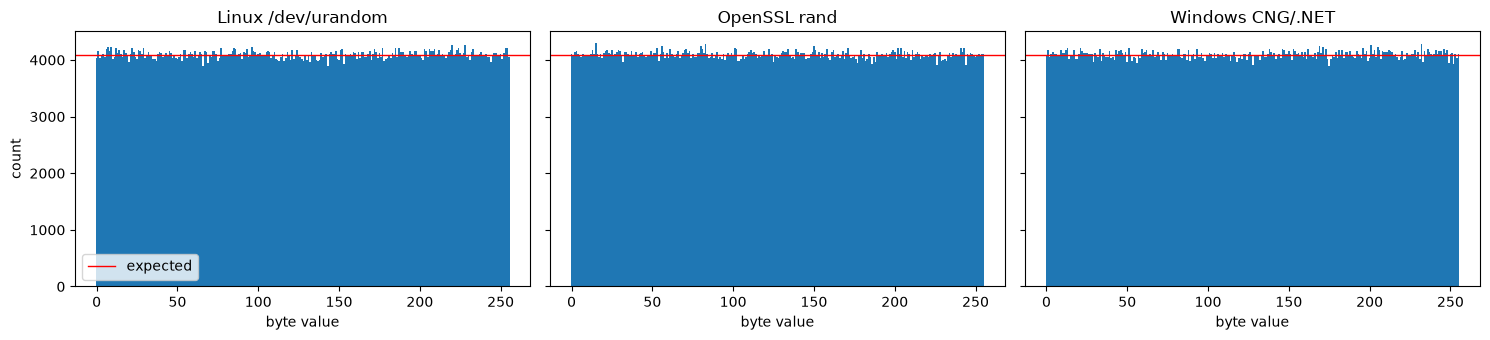

,Source,Min count,Max count,Expected count,Std dev of counts
0,Linux /dev/urandom,3892,4260,4096.0,65.98
1,OpenSSL rand,3918,4291,4096.0,61.59
2,Windows CNG/.NET,3885,4283,4096.0,65.06


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, (name, x) in zip(axes, data.items()):
    counts = np.bincount(x, minlength=256)
    ax.bar(range(256), counts, width=1.0)
    ax.axhline(len(x) / 256, color="red", linewidth=1, label="expected")
    ax.set_title(name)
    ax.set_xlabel("byte value")
axes[0].set_ylabel("count")
axes[0].legend()
plt.tight_layout()
plt.show()

summary = []
for name, x in data.items():
    c = np.bincount(x, minlength=256)
    summary.append([name, c.min(), c.max(), len(x) / 256, round(c.std(), 2)])
pd.DataFrame(summary, columns=["Source", "Min count", "Max count", "Expected count", "Std dev of counts"])

### 2.2 Bit distribution

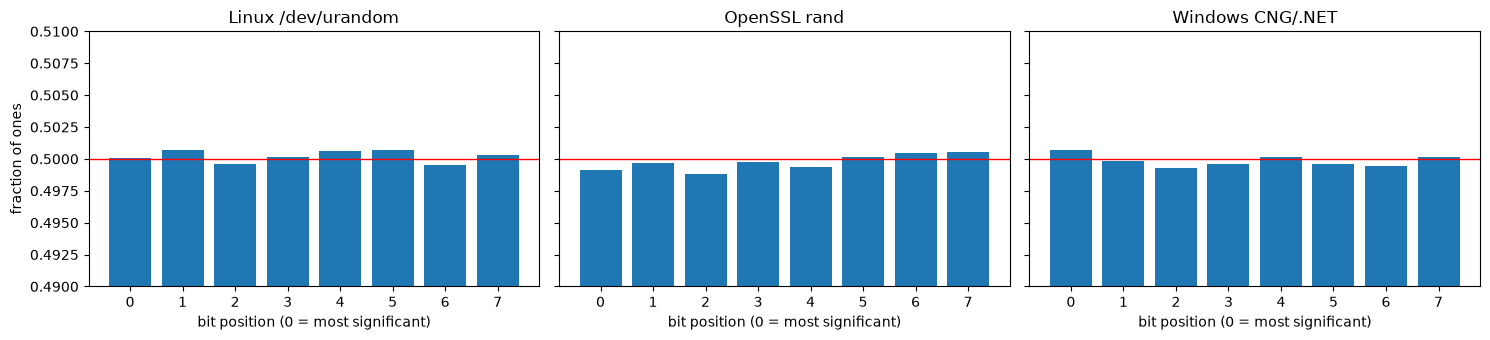

,Source,Total ones,Total zeros,% ones
0,Linux /dev/urandom,4196061,4192547,50.0209
1,OpenSSL rand,4192094,4196514,49.9737
2,Windows CNG/.NET,4193080,4195528,49.9854


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
bit_rows = []
for ax, (name, x) in zip(axes, data.items()):
    bits = np.unpackbits(x.reshape(-1, 1), axis=1)      # shape (N, 8)
    per_position = bits.mean(axis=0)                     # fraction of ones in each bit position
    ax.bar(range(8), per_position)
    ax.axhline(0.5, color="red", linewidth=1)
    ax.set_ylim(0.49, 0.51)
    ax.set_title(name)
    ax.set_xlabel("bit position (0 = most significant)")
    bit_rows.append([name, int(bits.sum()), int(bits.size - bits.sum()), round(bits.mean() * 100, 4)])
axes[0].set_ylabel("fraction of ones")
plt.tight_layout()
plt.show()

pd.DataFrame(bit_rows, columns=["Source", "Total ones", "Total zeros", "% ones"])

### 2.3 Repeated patterns

In [4]:
def duplicate_words(x, word_bytes=4):
    # split into non-overlapping words and count repeated words
    m = len(x) // word_bytes
    words = x[: m * word_bytes].reshape(m, word_bytes)
    values = np.zeros(m, dtype=np.uint64)
    for i in range(word_bytes):
        values = (values << np.uint64(8)) | words[:, i].astype(np.uint64)
    duplicates = m - len(np.unique(values))
    space = 256 ** word_bytes
    expected = m * (m - 1) / (2 * space)        # birthday-problem estimate
    return m, duplicates, expected

pat_rows = []
for name, x in data.items():
    m, dup, exp = duplicate_words(x, 4)
    pat_rows.append([name, m, dup, round(exp, 2)])
pd.DataFrame(pat_rows, columns=["Source", "4-byte words", "Repeated words (observed)", "Repeated words (expected by chance)"])

,Source,4-byte words,Repeated words (observed),Repeated words (expected by chance)
0,Linux /dev/urandom,262144,12,8.0
1,OpenSSL rand,262144,17,8.0
2,Windows CNG/.NET,262144,8,8.0


With 262,144 four-byte words in a space of 2^32 possible values, pure chance gives about **8** repeats
(birthday paradox). Seeing roughly that many is normal. Seeing hundreds or thousands would mean a pattern.

### 2.4 Serial correlation

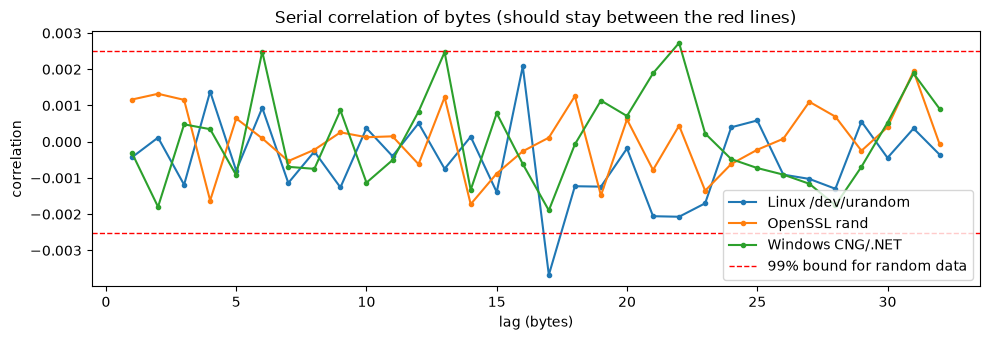

In [5]:
def autocorr(x, lag):
    a = x[:-lag].astype(float)
    b = x[lag:].astype(float)
    return np.corrcoef(a, b)[0, 1]

LAGS = range(1, 33)
fig, ax = plt.subplots(figsize=(10, 3.5))
for name, x in data.items():
    ax.plot(list(LAGS), [autocorr(x, k) for k in LAGS], marker="o", markersize=3, label=name)
bound = 2.576 / np.sqrt(len(next(iter(data.values()))))   # 99% bound for random data
ax.axhline(bound, color="red", linestyle="--", linewidth=1)
ax.axhline(-bound, color="red", linestyle="--", linewidth=1, label="99% bound for random data")
ax.set_xlabel("lag (bytes)")
ax.set_ylabel("correlation")
ax.set_title("Serial correlation of bytes (should stay between the red lines)")
ax.legend()
plt.tight_layout()
plt.show()

## Part 3 (Task 3): Statistical tests

Every test gives a **p-value**.
- If the data is truly random, p-values are spread evenly between 0 and 1.
- We **fail** a test when `p < 0.01`.
- A truly random source still fails any single test about 1% of the time just by chance, so **one failure does not prove a problem**. A real problem fails again and again, and usually fails badly (p close to 0).

| Test | What it checks |
|---|---|
| Byte chi-square | all 256 byte values equally likely |
| Monobit (frequency) | number of 1-bits vs 0-bits is balanced |
| Runs | runs of identical bits are not too long or too short |
| Pair chi-square | all 65,536 two-byte combinations equally likely |
| Serial correlation (lag 1) | a byte does not depend on the previous byte |
| Repeated 4-byte words | repeats match what chance predicts (Poisson) |

In [6]:
def test_byte_chi2(x):
    return stats.chisquare(np.bincount(x, minlength=256)).pvalue

def test_monobit(x):
    bits = np.unpackbits(x)
    n = bits.size
    s = abs(2 * int(bits.sum()) - n) / np.sqrt(n)
    return erfc(s / np.sqrt(2))

def test_runs(x):
    bits = np.unpackbits(x)
    n = bits.size
    pi = bits.mean()
    if abs(pi - 0.5) >= 2 / np.sqrt(n):          # prerequisite of the NIST runs test
        return 0.0
    v = 1 + int(np.count_nonzero(bits[1:] != bits[:-1]))
    return erfc(abs(v - 2 * n * pi * (1 - pi)) / (2 * np.sqrt(2 * n) * pi * (1 - pi)))

def test_pair_chi2(x):
    m = len(x) // 2
    pairs = x[: 2 * m].reshape(m, 2).astype(np.int64)
    idx = pairs[:, 0] * 256 + pairs[:, 1]
    return stats.chisquare(np.bincount(idx, minlength=65536)).pvalue

def test_serial_corr(x):
    r = autocorr(x, 1)
    z = r * np.sqrt(len(x))
    return 2 * stats.norm.sf(abs(z))

def test_duplicates(x):
    m, dup, exp = duplicate_words(x, 4)
    return stats.poisson.sf(dup - 1, exp)          # P(at least `dup` repeats by chance)

TESTS = {
    "Byte chi-square":        test_byte_chi2,
    "Monobit":                test_monobit,
    "Runs":                   test_runs,
    "Pair chi-square":        test_pair_chi2,
    "Serial corr. (lag 1)":   test_serial_corr,
    "Repeated 4-byte words":  test_duplicates,
}

def run_all(sources):
    table = {}
    for name, x in sources.items():
        col = {}
        for tname, fn in TESTS.items():
            p = float(fn(x))
            col[tname] = f"{p:.4f}  {'PASS' if p >= ALPHA else 'FAIL'}"
        table[name] = col
    return pd.DataFrame(table)

results = run_all(data)
results

,Linux /dev/urandom,OpenSSL rand,Windows CNG/.NET
Byte chi-square,0.2209 PASS,0.7832 PASS,0.3270 PASS
Monobit,0.2250 PASS,0.1270 PASS,0.3980 PASS
Runs,0.8835 PASS,0.5244 PASS,0.2608 PASS
Pair chi-square,0.9300 PASS,0.6055 PASS,0.7539 PASS
Serial corr. (lag 1),0.6600 PASS,0.2330 PASS,0.7491 PASS
Repeated 4-byte words,0.1119 PASS,0.0037 FAIL,0.5470 PASS


### Interpretation

- Look at the table above. Each cell shows the p-value and PASS/FAIL.
- If all three sources pass (or fail only one test with a p-value only slightly below 0.01), that is exactly what we expect from good random data. It means **no statistical weakness was detected** in these 1 MiB samples.
- If a test fails, run the generator again with fresh data and re-test. A random source fails by chance now and then; a broken source fails every time.
- Passing does **not** prove the generators are cryptographically secure. Part 5 shows why.

## Part 4 (Task 4): How Linux and Windows generate secure random data

### Linux
- **Interfaces:** `/dev/urandom`, `/dev/random`, the `getrandom()` system call, and `get_random_bytes()` inside the kernel. Since Linux 5.6, `/dev/random` and `/dev/urandom` behave the same way once the generator is initialised.
- **Entropy sources (unpredictable input):** timing of interrupts, disk and input-device activity, CPU timing jitter, hardware generators such as RDRAND/RDSEED when available, and a seed passed in at boot by the bootloader/firmware.
- **Collecting entropy:** all inputs are mixed into an *input pool* using the **BLAKE2s** hash function.
- **Producing output:** a seed taken from the pool keys a **ChaCha20** stream cipher, which expands it into as many random bytes as needed (a per-CPU ChaCha20 instance keeps this fast).
- **Fast key erasure:** after generating output, the key is immediately overwritten with fresh bytes, so a later break-in cannot reveal earlier outputs (backtracking resistance).
- **Reseeding:** the generator is reseeded regularly from the pool, so new entropy keeps flowing in.
- **Blocking:** `getrandom()` only blocks at early boot until the generator has been seeded once. After that it never blocks.

### Windows
- **Interfaces:** CNG function `BCryptGenRandom` (the modern API). Older `CryptGenRandom` and `RtlGenRandom` end up in the same generator. In .NET, `RandomNumberGenerator` / `RNGCryptoServiceProvider` call into it.
- **Structure:** a hierarchy of generators. A *root RNG* is seeded from entropy pools, and fast *per-processor* generators are seeded from the root and answer requests.
- **Algorithm:** the output generator is **AES-CTR-DRBG** following NIST SP 800-90.
- **Entropy sources:** interrupt timing (the main one), plus the initial seeding from a saved seed file, external entropy, the TPM, RDRAND/RDSEED, the ACPI OEM0 table, UEFI entropy and the current time. Entropy pools are hashed with **SHA-512** when used.
- **Reseeding:** the root RNG is reseeded periodically from the entropy pools.

### OpenSSL `rand`
OpenSSL does not read raw hardware entropy by itself. It runs its own DRBG (AES-based CTR-DRBG by default in OpenSSL 3.x) and seeds it from the operating system's generator (on Linux that is the kernel generator above). So `openssl rand` output is "a DRBG on top of the OS RNG".

### Why the three outputs look the same statistically
All three are **cryptographically secure pseudo-random number generators (CSPRNGs)**: a small secret seed (high entropy) is expanded by a strong cipher (ChaCha20 or AES) into a long stream that is indistinguishable from random noise. A good cipher's output passes every statistical test by design.

## Part 5 (Task 5): Comparison and why tests are not enough

### Comparison table

| | Linux | Windows | OpenSSL `rand` |
|---|---|---|---|
| Main interface | `/dev/urandom`, `getrandom()` | `BCryptGenRandom` (CNG), .NET `RandomNumberGenerator` | `openssl rand` / `RAND_bytes` |
| Output generator | ChaCha20 | AES-CTR-DRBG (NIST SP 800-90) | AES-based CTR-DRBG (OpenSSL 3.x default) |
| Entropy pool hash | BLAKE2s | SHA-512 | uses the OS generator as its seed source |
| Entropy sources | interrupts, disk/input timing, jitter, RDRAND/RDSEED, boot seed | interrupt timing, seed file, TPM, RDRAND/RDSEED, UEFI, time | OS generator |
| Reseeding | continuous / periodic | periodic from entropy pools | periodic, from the OS |
| Structure | one input pool, per-CPU ChaCha20 | root RNG + per-processor generators | one DRBG per library context/thread |

### Experiment: statistics vs security

Below we create three data sets of 1 MiB and run the same tests:
1. **Linux `/dev/urandom`** as the good reference.
2. **A deliberately bad generator** (low byte of a simple linear congruential generator). The tests should catch it.
3. **A *predictable* generator** (Python's Mersenne Twister seeded with a guessable seed such as a timestamp). It looks random to the tests, but an attacker can recover everything.

In [7]:
N = 1024 * 1024

# 2. bad generator: low byte of an LCG
def bad_lcg(n, seed=1):
    out = bytearray(n)
    state = seed
    for i in range(n):
        state = (1103515245 * state + 12345) & 0x7FFFFFFF
        out[i] = state & 0xFF
    return np.frombuffer(bytes(out), dtype=np.uint8)

# 3. predictable generator: Mersenne Twister with a timestamp-like seed
SECRET_SEED = 1_730_000_123           # "the time the key was generated"
mt_bytes = random.Random(SECRET_SEED).randbytes(N)

experiment = {
    "Linux /dev/urandom (good)": data["Linux /dev/urandom"],
    "Bad LCG (low byte)":        bad_lcg(N),
    "Mersenne Twister, guessable seed": np.frombuffer(mt_bytes, dtype=np.uint8),
}
run_all(experiment)

,Linux /dev/urandom (good),Bad LCG (low byte),"Mersenne Twister, guessable seed"
Byte chi-square,0.2209 PASS,1.0000 PASS,0.5075 PASS
Monobit,0.2250 PASS,1.0000 PASS,0.0390 PASS
Runs,0.8835 PASS,0.9994 PASS,0.2363 PASS
Pair chi-square,0.9300 PASS,0.0000 FAIL,0.2501 PASS
Serial corr. (lag 1),0.6600 PASS,0.0000 FAIL,0.8172 PASS
Repeated 4-byte words,0.1119 PASS,0.0000 FAIL,0.2834 PASS


**What to notice**
- The **bad LCG** fails several tests, so the statistical tests catch it.
- The **Mersenne Twister with a guessable seed** passes (or looks just like the good source), yet it is **not secure**. The next cell proves it.

In [8]:
# Attacker: sees only the FIRST 16 BYTES of output, and knows the seed is a timestamp
# somewhere within +/- 50,000 seconds of 1_730_000_000. Brute-force every seed.
observed = mt_bytes[:16]
start = time.perf_counter()
found = None
for guess in range(1_730_000_000 - 50_000, 1_730_000_000 + 50_000):
    if random.Random(guess).randbytes(16) == observed:
        found = guess
        break
elapsed = time.perf_counter() - start

print("Seed recovered:", found, "| correct:", found == SECRET_SEED)
print(f"Time taken: {elapsed:.2f} seconds for up to 100,000 guesses")

# With the seed, the attacker regenerates ALL 1 MiB of 'random' data
rebuilt = random.Random(found).randbytes(N)
print("Whole 1 MiB stream reproduced exactly:", rebuilt == mt_bytes)

Seed recovered: 1730000123 | correct: True
Time taken: 0.41 seconds for up to 100,000 guesses
Whole 1 MiB stream reproduced exactly: True


### Why passing statistical tests does NOT guarantee cryptographic security

1. **Tests only look at the output.** They ask "does this data look random?" Cryptography asks a harder question: "can an attacker who knows the algorithm and has seen some output predict the rest?" The Mersenne Twister example passes the tests yet is fully predictable once the seed (or enough output) is known.
2. **Small seed space.** Output can look perfect while the real secret is tiny (a timestamp, a process ID). The attacker searches the seed space, not the output space. Entropy of the *seed* is what matters, and tests cannot measure it.
3. **Deterministic algorithms always pass if they are good mixers.** Even a trivial program such as `SHA-256(key || counter)` produces output that passes every test, but anyone with `key` can reproduce it.
4. **Backdoors and weak design are invisible to statistics.** The Dual_EC_DRBG generator is the widely reported example: its output looks random, but whoever knows a special relationship between its constants can predict it.
5. **Statistics are finite.** A test on 1 MiB can only find flaws large enough to show up in 1 MiB. Passing means "no weakness found", not "no weakness exists".
6. **What really provides security:** (a) a high-entropy seed from unpredictable physical events, (b) a strong, well-reviewed algorithm (ChaCha20, AES-CTR-DRBG), (c) regular reseeding, (d) protection of internal state, and (e) correct use of the API (use `getrandom()` / `BCryptGenRandom` / `secrets`, never `random` or `rand()` for keys).

### Conclusion
`/dev/urandom`, `openssl rand` and Windows CNG/.NET all produce output that is statistically indistinguishable from random, which is what we would expect from CSPRNGs built on ChaCha20 or AES. They are suitable for cryptographic use, but the reason is their **design** (entropy sources, strong cipher, reseeding), not the fact that they passed our tests. Statistical tests are a useful sanity check for detecting broken generators, not a proof of security.